In [1]:
%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')

import sys
sys.path.insert(0, "../../")

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

Connecting to 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

## Pre-requisites

This notebook is a continuation of `2_seriatim_data_glm.ipynb`.  Please ensure you are comfortable with the following concepts before using this notebook:

 * The relationship between the Design Matrix and the $\beta$'s in a GLM

 * The `glum` package for fitting GLMs


## Advanced GLMs: Selection Factors

Selection factors are used to capture *underwriting wear-off*. In actuarial thinking, the effects of underwriting diminish steadily over a period of 5-25 years. How long it takes to diminish depends heavily on how it was originally underwritten, with fully-underwritten business typically lasting 25 years or more.

At the end of the selection period, the selection factor is expected to exactly `1.0`. This is so the *ultimate mortality rate* now drives the expected mortality. Putting this all together, here are the **requirements for selection factors:**

 1. The factor should start at less than 1.0, likely something like `0.5`.
 2. The factor should rapidly increase in the first few years.
 3. Near the end of the selection period, it should gradually increase to `1.0`, 
 4. For all years beyond the end of the selection period, the factor should remain at `1.0`

#### Selection Factor Tables

Selection factors are a function of policy year, i.e. the selection factor table depends only on policy year (and likely issue age group). We would expect a selection factor table to look something like this for a 5-year selection period.

| Policy Year | Issue Age < 50 | Issue Age 50-65  | Issue Age 66+ |
|-------------|----------------|------------------|---------------|
|  1          |  0.50          |     0.45         |  0.40         |
|  2          |  0.67          |     0.67         |  0.69         |
|  3          |  0.80          |     0.79         |  0.82         |
|  4          |  0.88          |     0.86         |  0.94         |
|  5          |  0.93          |     0.97         |  0.98         |
|  6+         |  1.00          |     1.00         |  1.00         |  

Note the following important properties:

 * In the first policy year, selection is strongest (lowest factor) for younger issue ages.
 * The effect of selection wears-off rapidly in the first few years, and then gradually as we reach the end of the selection period.

#### Solving for Selection Factors

A **power function** is defined as follows:

$$
f(x) = c \times x^p
$$

We will re-write this function using *policy year* as $x$:

$$
f(\text{policy year}) = c \times \text{policy year}^p
$$

Both $c$ and $p$ are free parameters, meaning we have to solve for them.  Let's find the values of $c$ and $p$ that are closest to the `Issue Age < 50` factors in the above table. We can use a simplification based on the form of the power function:

 * When the policy year is 1, we get $f(1) = c \times 1^p = c \times 1 = c$
    * $1^p = 1$ for all p.
    * So to fit this set of factors with a power function, we know that $c = 0.5$ 

 * Next we need to use an important simplification. We want $f(6) = 1.0$, since the factors need to end at 1.0 at the end of the selection period. This will not create a perfect fit to the table, but it will be close.  We need to plug the value of $c$ from above into our equation, and set it equal to $1.0$, since this is how we want our selection factor to behave:

 $$
    f(6) = c \times 6^p = (0.5) \times 6^p = 1.0 
 $$

* Since we have only one unknown ($p$), we can now solve the equation

$$
    0.5 \times 6^p = 1.0  \\[0.5em]
    \log( 0.5 \times 6^p) = \log(1.0) = 0  \\[0.5em]
    p \times \log(6) = -1 \times \log(0.5) \\[0.5em]
    p = \frac{-1 \times \log(0.5)}{\log(6)} \approx 0.387
$$

Let's now compare the solved values to the table 

In [2]:
import pandas as pd 

parameter_c = 0.5
parameter_p = 0.387
policy_years = list(range(1, 7)) # stops at 6, range goes up to end(7) - 1

# from the table of Issue Age < 50 selection factors that we made-up
table_values = [0.5, 0.67, 0.80, 0.88, 0.93, 1.0]

# helper function to calculate factor = c * pol_yr ^ p (power function)
calc_pwr_func = lambda pol_yr, c, p : c * pol_yr ** p 

# calculate the power function value
calculated_values = [calc_pwr_func(pol_yr, parameter_c, parameter_p) for pol_yr in policy_years]

pd.DataFrame({
    "Policy Year": policy_years,
    "Table Values": table_values,
    "Calculated Values": calculated_values
})


,Policy Year,Table Values,Calculated Values
0,1,0.50,0.500000
1,2,0.67,0.653836
2,3,0.80,0.764920
3,4,0.88,0.855002
4,5,0.93,0.932119
5,6,1.00,1.000264


#### Good News: How to solve for selection factors with a GLM 

GLMs can solve anything that is in *linear form*, like :  $\beta_0 + \beta_1 \times x$ 

A Poisson GLM solves the following linear equation:

$$
 \text{actual claims} = \text{exposure} \times q_x = \text{exposure} \times \exp[ \beta_0 + \beta_1 \times x ] 
$$

So when we want to include a selection factor, modeled as a power function, this becomes: 

$$
    \text{actual claims} = \text{exposure} \times \big( c \times \text{policy year}^p \big) \times \exp[ \beta_0 + \beta_1 \times x ]
$$

We can equivalently re-write it in linear form as 

$$
     \text{actual claims} = \exp[ \beta_0 + \beta_1 \times x + \log(c) + p \times \log(\text{policy year}) + \log(exposure)]
$$

Now we can set $\beta_3 = \log(c)$ and $\beta_4 = p$  and let the GLM solve them for us!

$$
    \exp[ \beta_0 + \beta_1 \times x + \beta_3 + \beta_4 \times \log(\text{policy year}) + \log(exposure)]
$$

To reverse this, and interpret the $\beta's$ as $c$ and $p$:

 * $\beta_3 = \log(c) \Rightarrow c = \exp[\beta_3]$
 
 * $\beta_4 = p$
 
 * Unlike we are used to, you do not need to use $e$ for the $p$ term!

#### Bad News: It's not perfect

But, we have an important constraint that a GLM cannot deal with: **the selection factor must end at 1.0**.

 * To work-around this limitation, we need to use a **2-step solving process**.
   
   1. Fit the GLM with free parameters for $c$ and $p$, we will likely end up with a selection factor at the end of the selection period that is **greater than 1.0**.

   2. Extract the selection factor table using a `PoissonGLMFactorAnalysis()` object, and divide all the values in each column by the maximum, so that the maximum value is 1.0.

   3. Apply this manually adjusted selection table as an offset, and refit the GLM with all terms except the selection period.

If this doesn't make sense, we'll look at a detailed example next 

### Two-Step Solving Process 

In [3]:
import formulaic as frm, pandas as pd, numpy as np
import glum as glm, plotnine as p9
from src.lib.glm import calc_path_stats, PoissonGLMFactorAnalysis

df_train = %sql select * from V_SERIATIM where Observation_Year < 2015 and POLICIES_EXPOSED > 0
df_test = %sql select * from V_SERIATIM where Observation_Year >= 2015 and POLICIES_EXPOSED > 0

df_train = df_train.DataFrame()
df_train["DATASET"] = "train"

df_test = df_test.DataFrame()
df_test["DATASET"] = "test"


df_data_summary = (
    pd
    .concat([df_train, df_test], axis=0)
    .groupby("DATASET")
    .agg({
        "POLICIES_EXPOSED":"sum",
        "EXPECTED_COUNT": "sum", 
        "CLAIM_COUNT": "sum"})
)
df_data_summary["A/E"] = df_data_summary["CLAIM_COUNT"] / df_data_summary["EXPECTED_COUNT"]
df_data_summary

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

,POLICIES_EXPOSED,EXPECTED_COUNT,CLAIM_COUNT,A/E
DATASET,,,,
test,8.681846e+06,32291.641244,33479.0,1.036770
train,9.554079e+06,35198.998501,37889.0,1.076423


#### Prerequisite: Create an ultimate mortality table

We will usually be given this information, so this isn't a necessity for actual fitting the model.  We just need an ultimate mortality table for this to be a clear-example, not for it to work.

In [4]:
# our ultimate table is sex and smoker distinct
ult_model_formula = frm.Formula.from_spec("~ cr(ATTAINED_AGE, knots=[30, 50, 60])*GENDER*SMOKER_STATUS")

ult_X_mat_train = ult_model_formula.get_model_matrix(df_train)
ult_y_train = df_train["CLAIM_COUNT"]
ult_offset_train = np.log(df_train["POLICIES_EXPOSED"])

glmnet_ult = glm.GeneralizedLinearRegressor(
    family="poisson",
    alpha_search=True,
    min_alpha_ratio=1e-6
)

glmnet_ult.fit(
    ult_X_mat_train,
    y = ult_y_train,
    offset = ult_offset_train
)

# append ultimate predictions to train data
df_train["EXPECTED_COUNT_ULT"] = glmnet_ult.predict(ult_X_mat_train, offset=ult_offset_train)

# append ultimate predictions to the test data
ult_X_mat_test = ult_model_formula.get_model_matrix(df_test)
ult_y_test = df_test["CLAIM_COUNT"]
ult_offset_test = np.log(df_test["POLICIES_EXPOSED"])
df_test["EXPECTED_COUNT_ULT"] = glmnet_ult.predict(ult_X_mat_test, offset=ult_offset_test)

# sanity check
{
    "train: A/E (Ult)": df_train["CLAIM_COUNT"].sum() / df_train["EXPECTED_COUNT_ULT"].sum(),
    "test: A/E (Ult)": df_test["CLAIM_COUNT"].sum() / df_test["EXPECTED_COUNT_ULT"].sum()
}

{'train: A/E (Ult)': np.float64(0.9999359775897498),
 'test: A/E (Ult)': np.float64(0.9428066589809807)}

#### Selection Effect

* To see the missing selection effects, we'll use a standard A/E plot by issue age group. This will help us make an educated guess about the **length of the selection period**.

  * Using XGBoost with SHAP is also quite helpful here, so consider using that as well. You can see an example of this in `1_seriatim_data_analysis.ipynb`.

  * Selection is pretty weak at younger ages, so sometimes we see strange patterns that aren't acceptable, like decreasing (rather than increasing) factors.  This is why it's important that the first issue age bin is pretty wide, like ages less than 50.  We also expect to be **strongest** at older ages in the earlier years.

    * If you are getting weird selection factors at younger ages, try increasing the bin size, or structure your model to not use selection for those issue ages (especially for Juveniles).
  
  * Policies issued to juveniles are also not usually underwritten, so the selection effect may not be apparent, because it isn't really there!

/tmp/ipykernel_33253/3227335946.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 8 rows containing missing values.


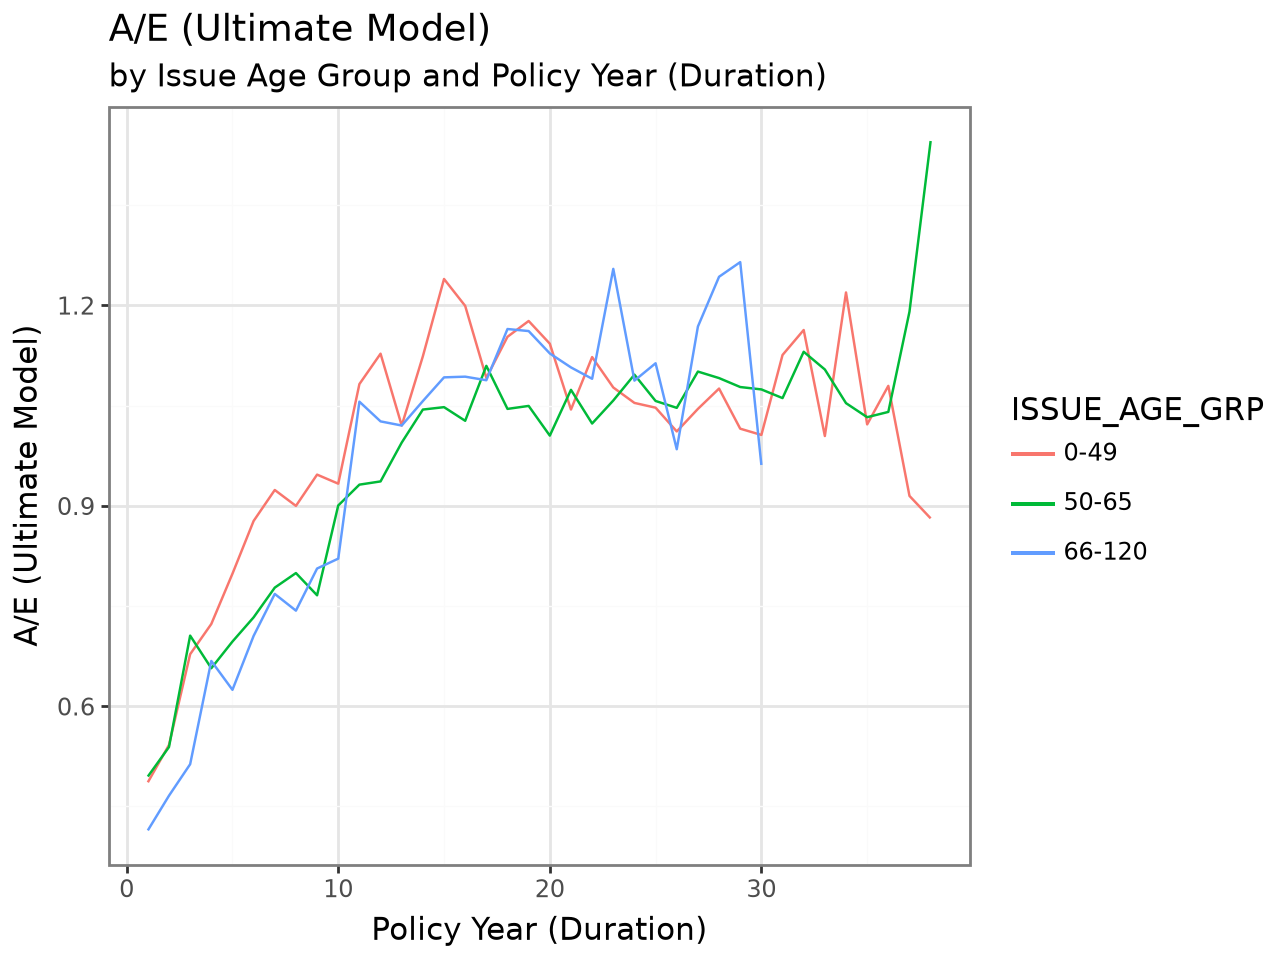

In [5]:
# create bins for issue age groups, since our selection factors will vary by this
def apply_age_bins(df):
    df["ISSUE_AGE_GRP"] = pd.cut(
        df["ISSUE_AGE"],
        bins=[0, 49, 65, 120],
        labels=["0-49", "50-65", "66-120"],
        include_lowest=True,
        ordered=False
    )
    return df

# apply issue age groups to train and test
df_train = apply_age_bins(df_train)
df_test = apply_age_bins(df_test)

df_all_data = pd.concat([df_train, df_test], axis=0)

df_plot_data = (
    df_all_data
    .groupby(["ISSUE_AGE_GRP", "DURATION"])
    .agg({"EXPECTED_COUNT_ULT": "sum", "CLAIM_COUNT": "sum"})
    .reset_index()
    .assign(
        AE_ULT = lambda x: x["CLAIM_COUNT"] / x["EXPECTED_COUNT_ULT"]
    )
)

(
    p9.ggplot(df_plot_data, p9.aes(x="DURATION", y="AE_ULT", color="ISSUE_AGE_GRP")) +
    p9.geom_line() +
    p9.theme_bw() +
    p9.ylab("A/E (Ultimate Model)") +
    p9.xlab("Policy Year (Duration)") +
    p9.ggtitle("A/E (Ultimate Model)", "by Issue Age Group and Policy Year (Duration)")
)

#### Selection Period Analysis

Using the above plot, we'll assume the following sselection period lengths:

 * 0-49   : 15 year selection period (factor = 1.0 in year 16+)
 * 50-65  : 20 year selection period
 * 66-120 : 25 year selection period

Note that the A/E is the lowest for older ages in policy year 1. To restate an important observation, selection is generally stronger for older ages.

Practically speaking, we would defer to the actuaries on this decision, but it's not unusualy for different issue ages to have different selection period lengths. Some companies keep this simple and just use one selection period length for all ages. 

#### GLMs for Selection Factors: Setting up the Design Matrix

To fit a model with different selection periods for each age, we need **one power function per age-group**.  Since power functions have two parameters (by definition), we need  **two $\beta$'s per power-function**. 

  * One beta is the $c$ term, which is effectively an intercept for each power function
  * One beta is the $p$ term, which becomes a slope

We also want to control for other effects **other than selection** like face amount and preferred class.

Before combining all these requirements into a single design matrix, let's discuss how the **power functions will be modeled**.

 * By using $\log(\text{duration})$ in our formula, we are (cleverly) getting a power-function that can be solved by the GLM, as discussed above.

 * By interacting $\log(\text{duration})$ with issue age group, we are getting **one power function per age group** and the two associated betas for each. 
 
 Let's see this in action with formulaic. We'll **start simple by assuming a 20 year selection period** for all issue age groups, before moving onto the custom per-issue age group selection periods. 
 
  * In this introductary example, we are ignoring the other terms that we will eventually need to modeled, like preferred class and face amount.

In [6]:
# we need to cap the factor after 20 years, so that it does not change,
# to do this we set the Duration to the minimum of 20 or the duration for the data/row.
# This accomplishes our goal of having the selection period be CONSTANT after 20 years, 
# but we can't make the GLM set it to 1.0 (and we'll have to do this manually)
df_train["SEL_FACTOR_DURATION"] = df_train["DURATION"].apply(lambda x: min(20, x))

# to make this term into a power function, we have to take the log
df_train["LOG_SEL_FACTOR_DURATION"] = np.log(df_train["SEL_FACTOR_DURATION"])

# create 20-year selection factor for each issue age group 
model_sel_only_formula = frm.Formula.from_spec("~ LOG_SEL_FACTOR_DURATION * ISSUE_AGE_GRP - 1")

X_mat_sel_only = model_sel_only_formula.get_model_matrix(df_train)
X_mat_sel_only

,LOG_SEL_FACTOR_DURATION,ISSUE_AGE_GRP[0-49],ISSUE_AGE_GRP[50-65],ISSUE_AGE_GRP[66-120],LOG_SEL_FACTOR_DURATION:ISSUE_AGE_GRP[T.50-65],LOG_SEL_FACTOR_DURATION:ISSUE_AGE_GRP[T.66-120]
0,1.945910,0,1,0,1.945910,0.000000
1,2.944439,0,0,1,0.000000,2.944439
2,2.564949,1,0,0,0.000000,0.000000
3,1.098612,0,0,1,0.000000,1.098612
4,2.564949,1,0,0,0.000000,0.000000
...,...,...,...,...,...,...
1181754,1.791759,1,0,0,0.000000,0.000000
1181755,0.693147,0,1,0,0.693147,0.000000
1181756,1.098612,0,1,0,1.098612,0.000000
1181757,0.693147,0,0,1,0.000000,0.693147


#### Design Matrix Discussion

We have six columns in the above design matrix, so we will have six $\beta$'s in the GLM. 

 * Since there are 3 different power functions (one for each issue age group), and each has two parameters, $p$ and $c$, so we expect 6 parameters.

 * But the $\beta$'s don't individually map to $p$ and $c$ parameters, but in total they do.  We'll perform a manual calculation to convert the $\beta$'s to $p$ and $c$ parameters later. 

#### Fitting Selection Factors


In [8]:
# create 20-year selection factor for each issue age group 
model_sel_factor_solve = frm.Formula.from_spec(
    "~ np.log(SEL_FACTOR_DURATION) * ISSUE_AGE_GRP - 1")

X_mat_sel_factor_solve = model_sel_factor_solve.get_model_matrix(df_train)

# use the ultimate table as the offset
offset_sel_only = np.log(df_train["EXPECTED_COUNT_ULT"])
y_sel_only = df_train["CLAIM_COUNT"]

glmnet_sel_only = glm.GeneralizedLinearRegressor(
    family="poisson",
    alpha_search=True,
    min_alpha_ratio=1e-6
)

# fit the selection factors
glmnet_sel_only.fit(
    X_mat_sel_factor_solve,
    y = y_sel_only,
    offset = offset_sel_only
)

# pull out the factor analysis
factor_analysis = PoissonGLMFactorAnalysis(
    glmnet_sel_only.coef_table(),
    X_mat_sel_factor_solve.model_spec)

factor_analysis_tables = factor_analysis.get_factor_analysis(df_train)
beta_intercept = factor_analysis_tables[0]["factor"].values[0]

# calculate the selection factors. 
sel_factors = (
    factor_analysis_tables[1]
    .assign(
        DURATION = lambda x: np.exp(x["SEL_FACTOR_DURATION"]),
        # we don't always include the intercept, but here we must, because
        # there are no other non-selection terms in the model matrix, i.e.,
        # we are ONLY solving for selection, therefore the intercept is a part
        # of the selection table!
        FACTOR = lambda x: x["factor"] * beta_intercept
    )
)  

sel_factors.pivot(index="SEL_FACTOR_DURATION", columns="ISSUE_AGE_GRP", values="FACTOR")

ISSUE_AGE_GRP,0-49,50-65,66-120
SEL_FACTOR_DURATION,,,
1,0.536201,0.541939,0.434832
2,0.642979,0.636156,0.544002
3,0.715043,0.698691,0.620163
4,0.771020,0.746753,0.680582
5,0.817440,0.786298,0.731471
6,0.857435,0.820159,0.775863
7,0.892773,0.849922,0.815491
8,0.924559,0.876577,0.851451
9,0.953535,0.900780,0.884484


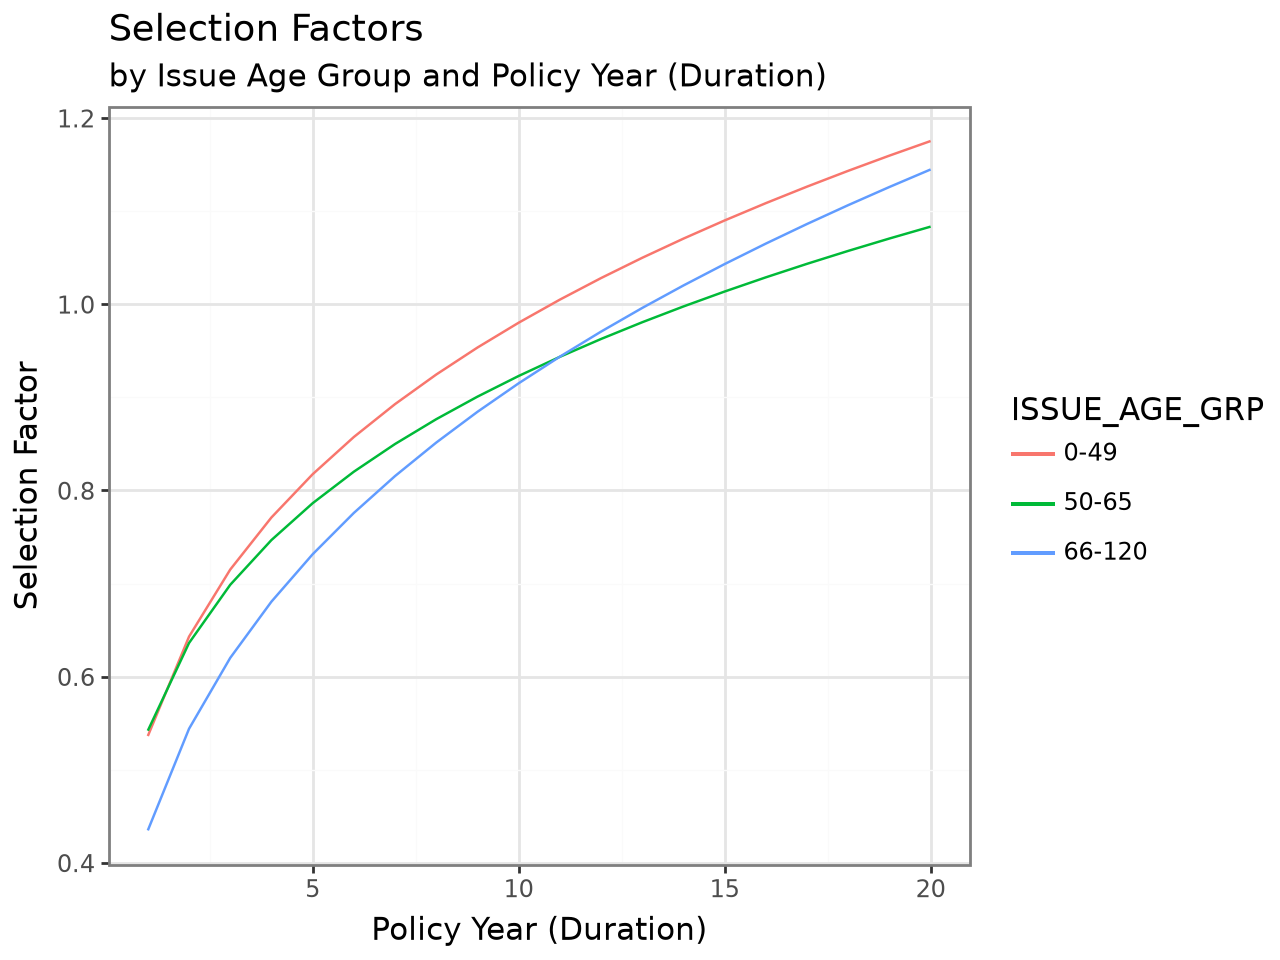

In [9]:
(
    p9.ggplot(sel_factors, p9.aes(x="SEL_FACTOR_DURATION", y="FACTOR", color="ISSUE_AGE_GRP")) +
    p9.geom_line() +
    p9.theme_bw() +
    p9.ylab("Selection Factor") +
    p9.xlab("Policy Year (Duration)") +
    p9.ggtitle("Selection Factors", "by Issue Age Group and Policy Year (Duration)")
)

/tmp/ipykernel_33253/2508544309.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 4 rows containing missing values.


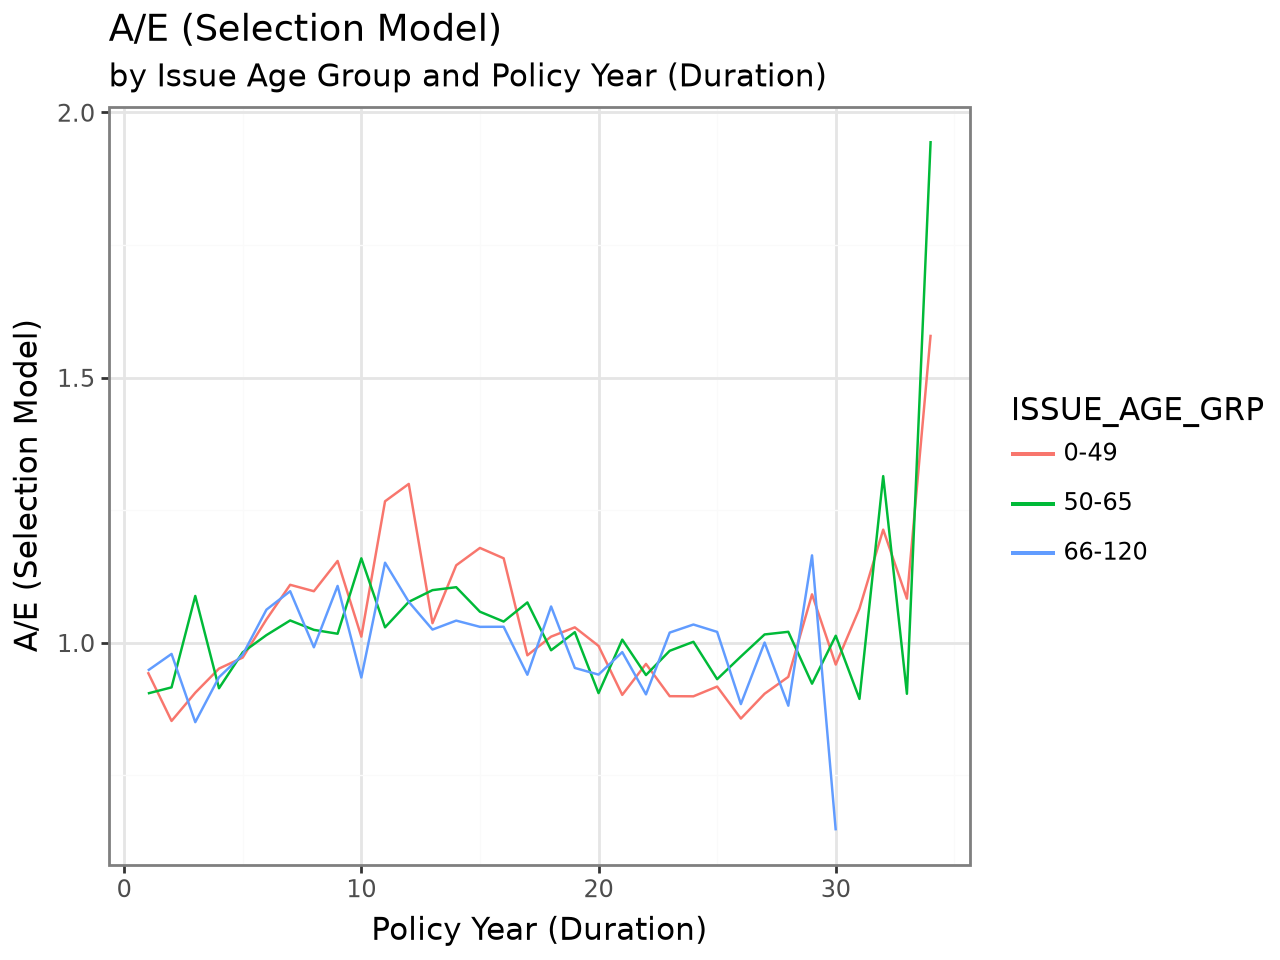

In [10]:
df_train["EXPECTED_COUNT_SEL"] = glmnet_sel_only.predict(X_mat_sel_factor_solve, offset=offset_sel_only)

df_plot = (
    df_train
    .groupby(["DURATION", "ISSUE_AGE_GRP"])
    .agg({"EXPECTED_COUNT_SEL": "sum", "CLAIM_COUNT": "sum"})
    .reset_index()
    .assign(AE_SEL = lambda x: x["CLAIM_COUNT"] / x["EXPECTED_COUNT_SEL"])
)

(
    p9.ggplot(df_plot, p9.aes(x="DURATION", y="AE_SEL", color="ISSUE_AGE_GRP")) +
    p9.geom_line() +
    p9.theme_bw() +
    p9.ylab("A/E (Selection Model)") +
    p9.xlab("Policy Year (Duration)") +
    p9.ggtitle("A/E (Selection Model)", "by Issue Age Group and Policy Year (Duration)")
)



#### Limitations

If you look at `SEL_FACTOR_DURATION = 20`, you'll notice that none of the factors end at 1.0. Unfortunately, we'll need to manually adjust the factors and feed them into the final model as an offset.

  * The manual adjustment is easy, we just **divide each column in the table by it's maximum**.

  * There are also some modifications that we need to layer on so that the overall impact of the limitation is minimal.  We'll see an end-to-end example shortly.

In [11]:
sel_factors = sel_factors.assign(
    FACTOR=lambda x: x["FACTOR"] / x.groupby("ISSUE_AGE_GRP")["FACTOR"].transform("max")
)

sel_factors.pivot(index="SEL_FACTOR_DURATION", columns="ISSUE_AGE_GRP", values="FACTOR")

/tmp/ipykernel_33253/2798120378.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


ISSUE_AGE_GRP,0-49,50-65,66-120
SEL_FACTOR_DURATION,,,
1,0.456178,0.500193,0.379809
2,0.547020,0.587152,0.475165
3,0.608329,0.644869,0.541688
4,0.655952,0.689229,0.594462
5,0.695444,0.725728,0.638912
6,0.729470,0.756980,0.677687
7,0.759534,0.784451,0.712300
8,0.786576,0.809052,0.743710
9,0.811228,0.831391,0.772563


#### Interpreting $\beta$'s in terms of $c$ and $p$

Using the $\beta$'s, let's calculate the $c$ and $p$ terms for each age group, one-by-one.

In [21]:
# get the betas from the fit to calculate c and p
glmnet_sel_only.coef_table()

intercept                                             -0.689548
np.log(SEL_FACTOR_DURATION)                            0.261997
ISSUE_AGE_GRP[0-49]                                    0.066302
ISSUE_AGE_GRP[50-65]                                   0.076947
ISSUE_AGE_GRP[66-120]                                 -0.143248
np.log(SEL_FACTOR_DURATION):ISSUE_AGE_GRP[T.50-65]    -0.030748
np.log(SEL_FACTOR_DURATION):ISSUE_AGE_GRP[T.66-120]    0.061158
Name: coef, dtype: float64

**Issue ages < 50 (0-49)**

$$
c = \exp\big[ \beta_{\text{Intercept}} + \beta_{\text{ISSUE\_AGE\_GRP[0-49]}} \big] = \exp\big[ -0.689 + 0.066 \big] \approx 0.536
$$

$$
p = \beta_{\text{log(SEL\_FACTOR\_DURATION)}} = 0.262
$$

You may be wondering why $p$ is not calculated using $\exp$.  This is not a mistake. See the *Solving for Selection Factors* section at the top of the notebook for a recap.

**Issue ages 50-65**

$$
c = \exp\big[ \beta_{\text{Intercept}} + \beta_{\text{ISSUE\_AGE\_GRP[50-65]}} \big] = \exp\big[-0.689 + 0.077 \big] \approx 0.542
$$

$$
p = \beta_{\text{log(SEL\_FACTOR\_DURATION)}} + \beta_{\text{log(SEL\_FACTOR\_DURATION):ISSUE\_AGE\_GRP[T.50-65])}} = 0.231
$$

Remember, whenever we have an interaction term, we ALSO need to add the base term. There is no interaction term for ages 0-49 due to colinearity.

**Issue ages 66-120**

$$
c = \exp\big[ \beta_{\text{Intercept}} + \beta_{\text{ISSUE\_AGE\_GRP[66-120]}} \big] = \exp\big[ -0.689 + -0.143 \big] \approx 0.435
$$

$$
p = \beta_{\text{log(SEL\_FACTOR\_DURATION)}} + \beta_{\text{log(SEL\_FACTOR\_DURATION):ISSUE\_AGE\_GRP[T.66-120])}} = 0.323
$$



#### Applying manually calculated select factors

Although we could've simply used a `PoissonGLMFactorAnalysis()` to do this manual work, or just call `predict()` with our fitted glm, let's apply the factors we just calculated and look at the resulting change in the A/E plot.

/tmp/ipykernel_33253/4227812452.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 4 rows containing missing values.


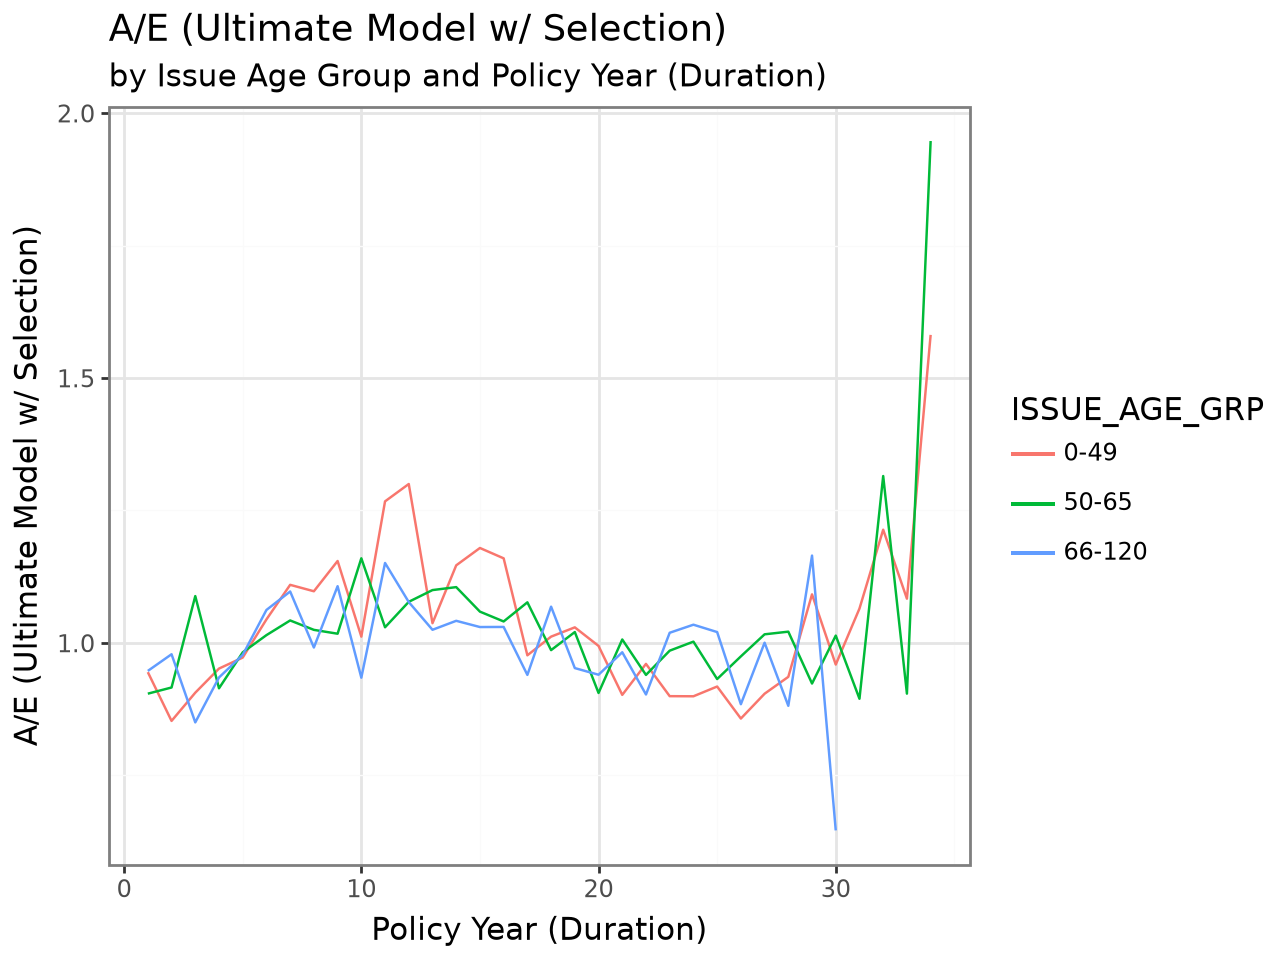

In [25]:
c_params = {
    "0-49": 0.536,
    "50-65": 0.542,
    "66-120": 0.435
}

p_params = {
    "0-49": 0.262,
    "50-65": 0.231,
    "66-120": 0.323
}

# calculate the power functions / selection factors,
# apply to the ultimate expected rate,
# and calculate the A/E for the resulting updated expected counts (now w/ selection)
df_train_w_sel = df_train.assign(
    PARAM_C=lambda x: x["ISSUE_AGE_GRP"].map(c_params).astype("float64"),
    PARAM_P=lambda x: x["ISSUE_AGE_GRP"].map(p_params).astype("float64"),
    SEL_FACTOR=lambda x: x["PARAM_C"] * (x["SEL_FACTOR_DURATION"] ** x["PARAM_P"]),
    EXP_COUNT_SEL=lambda x: x["EXPECTED_COUNT_ULT"] * x["SEL_FACTOR"]
)

df_plot_data = (
    df_train_w_sel
    .groupby(["ISSUE_AGE_GRP", "DURATION"])
    .agg({"EXP_COUNT_SEL": "sum", "CLAIM_COUNT": "sum"})
    .reset_index()
    .assign(
        AE_SEL=lambda x: x["CLAIM_COUNT"] / x["EXP_COUNT_SEL"]
    )
)

# we can see that our A/E trend by duration is now gone after applying the
# manually calculated selection factors!
(
    p9.ggplot(df_plot_data, p9.aes(x="DURATION", y="AE_SEL", color="ISSUE_AGE_GRP")) +
    p9.geom_line() +
    p9.theme_bw() +
    p9.ylab("A/E (Ultimate Model w/ Selection)") +
    p9.xlab("Policy Year (Duration)") +
    p9.ggtitle("A/E (Ultimate Model w/ Selection)", "by Issue Age Group and Policy Year (Duration)")
)

## Full Selection Factor Fitting Procedure

The previous example shows conceptually what we are doing to fit selection factors with GLMs, but it is overly simplistic for a few reasons:

 * The shape of the $\log(\text{policy year})$ term doesn't coverge to 1.0 fast enough near the end of the selection period.

 * The model is only fitting selection. Suppose we want factors for preferred class and face amount as well, we need a procedure for fitting selection with these other predictors.

   * **Important:** When fitting a selection model on an ultimate table, we typically also want to include an `attained_age` predictor to absorb any additional age-related mortality impacts beyond the end of the selection period. To repeat, if you are fitting selection include `attained_age`.

   * **But in this case:** We won't include `attained_age`, since we already used it in the ultimate table we built from this *exact* dataset.  When the ultimates come from a *different* dataset (e.g., industry tables), it needs to be included.

To fit multiple factors simultaneously, we need to fit two models and follow the below process:

 1. Fit a model with preferred class, face amount, and selection factors ontop of an ultimates table.

 2. Extract the selection factors from the model.

 3. Manually the extracted selection factors by the maximum, so that all selection factors reach 1.0 at the end of the selection period.

 4. Use the manually adjusted table as an offset to the ultimates table.

 5. Fit a second model with preferred class and face amounts using an offset that is the ultimates table + manually adjusted selection factors. 

### 1. Fit Model w/ Selection + All Other Predictors